# Dissertation Assignment 4
# GraphSAGE Baseline Implementation
**Submitted by:<br>
Urvi Sharma <br>
Roll No: AM.EN.P2ARI2022 <br>
Date : 11-Nov-2021**

In this implementation of the GraphSAGE algorithm we build a model that predicts links in the dataset. The problem is treated as a supervised link prediction problem on a homogeneous citation network.

In [1]:
import pandas as pd
#import os
import stellargraph as sg
from stellargraph.data import EdgeSplitter
from stellargraph.mapper import GraphSAGELinkGenerator
from stellargraph.layer import GraphSAGE, HinSAGE, link_classification
from tensorflow import keras
from sklearn import preprocessing, feature_extraction, model_selection

from stellargraph import globalvar
from stellargraph import StellarGraph 
%matplotlib inline

### Data Loading and Pre-Processing

In [2]:
df = pd.read_csv('normalized_ratings.csv')
df

,source,target,edge
0,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
1,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
2,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
3,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
4,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
...,...,...,...
3171,A2077NII5H62R2,B005AGO4LU,5.0
3172,A2IBS6PIPAGAB5,B005AGO4LU,5.0
3173,A1GTC5EVSJNCQ8,B005AGO4LU,5.0
3174,A311XHHLM12MUT,B005AGO4LU,5.0


In [3]:
reviews = pd.read_csv("reviews.csv")
reviews

,rating,reviewTime,reviewerID,productID,style,reviewerName,reviewText,summary,unixReviewTime,Size,Color
0,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Blue/Orange'}",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Blue/Orange
1,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Black (3746...",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Black (37467610) / Red/White
2,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Blue/Gray L...",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Blue/Gray Logo
3,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Blue (37867...",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Blue (37867638-99) / Yellow
4,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Blue/Pink'}",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Blue/Pink
...,...,...,...,...,...,...,...,...,...,...,...
3171,5,"07 2, 2018",A2077NII5H62R2,B005AGO4LU,"{'Size:': ' 8.5 B(M) US', 'Color:': ' Green Gl...",Amazon Customer,Perfect fit!,Five Stars,1530489600,8.5 B(M) US,Green Glow/Seaweed - Hasta - White
3172,5,"06 28, 2018",A2IBS6PIPAGAB5,B005AGO4LU,"{'Size:': ' 5 B(M) US', 'Color:': ' Wolf Grey/...",J. Avila,My favorite cross trainers!,Comfortable,1530144000,5 B(M) US,Wolf Grey/Black-pink Blast/White
3173,5,"06 25, 2018",A1GTC5EVSJNCQ8,B005AGO4LU,"{'Size:': ' 8 B(M) US', 'Color:': ' Blue Tint/...",Amazon Customer,Love them fit perfect,Five Stars,1529884800,8 B(M) US,Blue Tint/Green Glow/Hasta/White
3174,5,"06 20, 2018",A311XHHLM12MUT,B005AGO4LU,"{'Size:': ' 9 B(M) US', 'Color:': ' Blue Tint/...",Peter,Favorite Nike shoe ever! The flex sole is exce...,Love them!,1529452800,9 B(M) US,Blue Tint/Green Glow/Hasta/White


In [4]:
nr = reviews.drop(columns = ['rating','productID','reviewerName','summary','reviewText','unixReviewTime','style'])

In [5]:
nr = nr.drop_duplicates(subset=['reviewerID']).set_index('reviewerID')
nr.index.name = 'ID'
nr

,reviewTime,Size,Color
ID,,,
ALJ66O1Y6SLHA,"09 4, 2015",Big Boys,Blue/Orange
A3W11493KS6Z2L,"05 6, 2015",Little Boys,White/Black
A3HX4X3TIABWOV,"01 25, 2018",0,0
AW8UBYMNJ894V,"01 5, 2017",0,0
A265UZVOZWTTXQ,"10 17, 2016",0,0
...,...,...,...
A2077NII5H62R2,"07 2, 2018",8.5 M US,Green Glow/Seaweed - Hasta - White
A2IBS6PIPAGAB5,"06 28, 2018",5 M US,Wolf Grey/Black-pink Blast/White
A1GTC5EVSJNCQ8,"06 25, 2018",8 M US,Blue Tint/Green Glow/Hasta/White


In [6]:
pr = reviews.drop(columns = ['rating','reviewerID','reviewerName','summary','reviewText','unixReviewTime','style'])
pr

,reviewTime,productID,Size,Color
0,"09 4, 2015",B000K2PJ4K,Big Boys,Blue/Orange
1,"09 4, 2015",B000K2PJ4K,Big Boys,Black (37467610) / Red/White
2,"09 4, 2015",B000K2PJ4K,Big Boys,Blue/Gray Logo
3,"09 4, 2015",B000K2PJ4K,Big Boys,Blue (37867638-99) / Yellow
4,"09 4, 2015",B000K2PJ4K,Big Boys,Blue/Pink
...,...,...,...,...
3171,"07 2, 2018",B005AGO4LU,8.5 B(M) US,Green Glow/Seaweed - Hasta - White
3172,"06 28, 2018",B005AGO4LU,5 B(M) US,Wolf Grey/Black-pink Blast/White
3173,"06 25, 2018",B005AGO4LU,8 B(M) US,Blue Tint/Green Glow/Hasta/White
3174,"06 20, 2018",B005AGO4LU,9 B(M) US,Blue Tint/Green Glow/Hasta/White


In [7]:
pr = pr.drop_duplicates(subset=['productID']).set_index('productID')
pr.index.name = 'ID'

In [8]:
nr = nr.append(pr)
nr

,reviewTime,Size,Color
ID,,,
ALJ66O1Y6SLHA,"09 4, 2015",Big Boys,Blue/Orange
A3W11493KS6Z2L,"05 6, 2015",Little Boys,White/Black
A3HX4X3TIABWOV,"01 25, 2018",0,0
AW8UBYMNJ894V,"01 5, 2017",0,0
A265UZVOZWTTXQ,"10 17, 2016",0,0
...,...,...,...
B014IBJKNO,"03 28, 2016",7.5 M US,Cool Grey/Team Orange/White/Platinum
B01595OS62,"02 8, 2018",X-Large (16-18),Bluestone Wash
B016XAJLVO,"02 1, 2018",0,0


In [9]:
nr = pd.get_dummies(nr, columns = ['reviewTime','Size','Color'])
nr

,"reviewTime_01 1, 2017","reviewTime_01 10, 2017","reviewTime_01 10, 2018","reviewTime_01 11, 2018","reviewTime_01 12, 2017","reviewTime_01 13, 2017","reviewTime_01 15, 2017","reviewTime_01 18, 2017","reviewTime_01 18, 2018","reviewTime_01 20, 2017",...,Color_Plure Platinum/Blue Glow/Wolf Grey,Color_Pure Platinum/Blue Glow/Wolf Grey,Color_Racer Blue/Obsidian/Blue Tint,Color_Red,Color_Red/White/Blue,Color_White/Black,Color_White/Hyper Pink/Pure Platinum/Wolf Grey,Color_White/Metallic Silver/Black,Color_Wolf Grey/Black-pink Blast/White,Color_Wolf Grey/Platinum/White/Crimson
ID,,,,,,,,,,,,,,,,,,,,,
ALJ66O1Y6SLHA,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A3W11493KS6Z2L,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
A3HX4X3TIABWOV,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AW8UBYMNJ894V,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A265UZVOZWTTXQ,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
B014IBJKNO,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
B01595OS62,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
B016XAJLVO,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


The 'nr' dataframe created represents the feature vectors for the Graph.

### Graph Creation

In [10]:
G = StellarGraph({'ID' : nr},edges=df, edge_type_default="edge")

In [11]:
print(G.info())

StellarGraph: Undirected multigraph
 Nodes: 437, Edges: 3176

 Node types:
  ID: [437]
    Features: float32 vector, length 422
    Edge types: ID-edge->ID

 Edge types:
    ID-edge->ID: [3176]
        Weights: all 1 (default)
        Features: float32 vector, length 1


**Splitting data in train and test.**

In [12]:
# Define an edge splitter on the original graph G:
edge_splitter_test = EdgeSplitter(G)

# Randomly sample a fraction p=0.1 of all positive links, and same number of negative links, from G, and obtain the
# reduced graph G_test with the sampled links removed:
G_test, edge_ids_test, edge_labels_test = edge_splitter_test.train_test_split(
    p=0.1, method="global", keep_connected=True
)

** Sampled 317 positive and 317 negative edges. **


In [13]:
# Define an edge splitter on the reduced graph G_test:
edge_splitter_train = EdgeSplitter(G_test)

# Randomly sample a fraction p=0.1 of all positive links, and same number of negative links, from G_test, and obtain the
# reduced graph G_train with the sampled links removed:
G_train, edge_ids_train, edge_labels_train = edge_splitter_train.train_test_split(
    p=0.1, method="global", keep_connected=True
)

** Sampled 285 positive and 285 negative edges. **


In [14]:
print(G_train.info())

StellarGraph: Undirected multigraph
 Nodes: 437, Edges: 2574

 Node types:
  ID: [437]
    Features: float32 vector, length 422
    Edge types: ID-edge->ID

 Edge types:
    ID-edge->ID: [2574]
        Weights: all 1 (default)
        Features: none


In [15]:
print(G_test.info())

StellarGraph: Undirected multigraph
 Nodes: 437, Edges: 2859

 Node types:
  ID: [437]
    Features: float32 vector, length 422
    Edge types: ID-edge->ID

 Edge types:
    ID-edge->ID: [2859]
        Weights: all 1 (default)
        Features: none


In [16]:
batch_size = 20
epochs = 20
num_samples = [20, 10]

### GraphSAGE Implementation

In [17]:
train_gen = GraphSAGELinkGenerator(G_train, batch_size, num_samples)
train_flow = train_gen.flow(edge_ids_train, edge_labels_train, shuffle=True)

In [18]:
test_gen = GraphSAGELinkGenerator(G_test, batch_size, num_samples)
test_flow = test_gen.flow(edge_ids_test, edge_labels_test)

In [19]:
layer_sizes = [20, 20]
graphsage = GraphSAGE(
    layer_sizes=layer_sizes, generator=train_gen, bias=True, dropout=0.3
)

In [20]:
# Build the model and expose input and output sockets of graphsage model
# for link prediction
x_inp, x_out = graphsage.in_out_tensors()

Final link classification layer that takes a pair of node embeddings produced by GraphSAGE, applies a binary operator to them to produce the corresponding link embedding.

In [21]:
prediction = link_classification(
    output_dim=1, output_act="relu", edge_embedding_method="ip"
)(x_out)

link_classification: using 'ip' method to combine node embeddings into edge embeddings


Stack the GraphSAGE and prediction layers into a Keras model, and specify the loss

In [22]:
model = keras.Model(inputs=x_inp, outputs=prediction)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.binary_crossentropy,
    metrics=["acc"],
)

Evaluate the trained model on test links:

In [23]:
init_train_metrics = model.evaluate(train_flow)
init_test_metrics = model.evaluate(test_flow)

print("\nTrain Set Metrics of the initial (untrained) model:")
for name, val in zip(model.metrics_names, init_train_metrics):
    print("\t{}: {:0.4f}".format(name, val))

print("\nTest Set Metrics of the initial (untrained) model:")
for name, val in zip(model.metrics_names, init_test_metrics):
    print("\t{}: {:0.4f}".format(name, val))

32/32 [==============================] - 3s 98ms/step - loss: 0.8774 - acc: 0.5394

Train Set Metrics of the initial (untrained) model:
	loss: 0.8582
	acc: 0.5491

Test Set Metrics of the initial (untrained) model:
	loss: 0.8774
	acc: 0.5394


Train the model:

In [24]:
history = model.fit(train_flow, epochs=200, validation_data=test_flow, verbose=2)

Epoch 1/200
29/29 - 11s - loss: 0.7948 - acc: 0.5491 - val_loss: 0.7790 - val_acc: 0.6136
Epoch 2/200
29/29 - 7s - loss: 0.6895 - acc: 0.6193 - val_loss: 0.6828 - val_acc: 0.6593
Epoch 3/200
29/29 - 7s - loss: 0.6259 - acc: 0.6439 - val_loss: 0.6551 - val_acc: 0.6767
Epoch 4/200
29/29 - 7s - loss: 0.5470 - acc: 0.6947 - val_loss: 0.6089 - val_acc: 0.7019
Epoch 5/200
29/29 - 7s - loss: 0.5714 - acc: 0.6912 - val_loss: 0.5847 - val_acc: 0.7114
Epoch 6/200
29/29 - 7s - loss: 0.5235 - acc: 0.7351 - val_loss: 0.5671 - val_acc: 0.7161
Epoch 7/200
29/29 - 7s - loss: 0.4880 - acc: 0.7579 - val_loss: 0.5420 - val_acc: 0.7382
Epoch 8/200
29/29 - 7s - loss: 0.5176 - acc: 0.7351 - val_loss: 0.5728 - val_acc: 0.7003
Epoch 9/200
29/29 - 8s - loss: 0.4801 - acc: 0.7807 - val_loss: 0.5310 - val_acc: 0.7413
Epoch 10/200
29/29 - 11s - loss: 0.4573 - acc: 0.8123 - val_loss: 0.5108 - val_acc: 0.7634
Epoch 11/200
29/29 - 6s - loss: 0.4319 - acc: 0.8316 - val_loss: 0.5198 - val_acc: 0.7539
Epoch 12/200
29/2

Plot the training history:

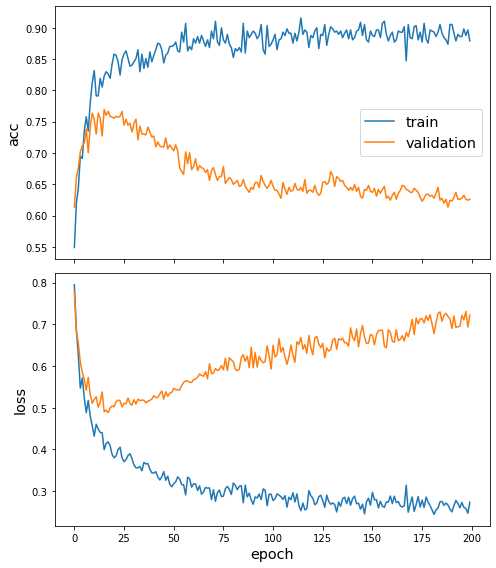

In [25]:
sg.utils.plot_history(history)

### Evaluation

In [26]:
train_metrics = model.evaluate(train_flow)
test_metrics = model.evaluate(test_flow)

print("\nTrain Set Metrics of the trained model:")
for name, val in zip(model.metrics_names, train_metrics):
    print("\t{}: {:0.4f}".format(name, val))

print("\nTest Set Metrics of the trained model:")
for name, val in zip(model.metrics_names, test_metrics):
    print("\t{}: {:0.4f}".format(name, val))

32/32 [==============================] - 3s 77ms/step - loss: 0.7204 - acc: 0.6199: 1s - loss: 0.709 - ETA: 0s - loss: 0.7452 - acc:

Train Set Metrics of the trained model:
	loss: 0.1349
	acc: 0.9737

Test Set Metrics of the trained model:
	loss: 0.7204
	acc: 0.6199


### Graph Embedding Visualization

In [27]:
#for embedding plot
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from stellargraph.mapper import GraphSAGENodeGenerator
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [28]:
x_inp_src = x_inp[0::2]
x_out_src = x_out[0]
embedding_model = keras.Model(inputs=x_inp_src, outputs=x_out_src)

In [29]:
node_subjects = pd.read_csv('node_subject.csv')
node_subjects = node_subjects.set_index('ID').squeeze()
node_subjects

ID
ALJ66O1Y6SLHA    source
ALJ66O1Y6SLHA    source
ALJ66O1Y6SLHA    source
ALJ66O1Y6SLHA    source
ALJ66O1Y6SLHA    source
                  ...  
B005AGO4LU       target
B005AGO4LU       target
B005AGO4LU       target
B005AGO4LU       target
B005AGO4LU       target
Name: subject, Length: 6352, dtype: object

In [30]:
node_ids = node_subjects.index
node_gen = GraphSAGENodeGenerator(G, batch_size, num_samples).flow(node_ids)

In [31]:
node_embeddings = embedding_model.predict(node_gen, workers=4, verbose=1)

318/318 [==============================] - 16s 50ms/step


In [32]:
node_subject = node_subjects.astype("category").cat.codes

X = node_embeddings
if X.shape[1] > 2:
    transform = TSNE  # PCA

    trans = transform(n_components=2)
    emb_transformed = pd.DataFrame(trans.fit_transform(X), index=node_ids)
    emb_transformed["label"] = node_subject
else:
    emb_transformed = pd.DataFrame(X, index=node_ids)
    emb_transformed = emb_transformed.rename(columns={"0": 0, "1": 1})
    emb_transformed["label"] = node_subject

In [33]:
emb_transformed

,0,1,label
ID,,,
ALJ66O1Y6SLHA,-2.229249,-87.102730,0
ALJ66O1Y6SLHA,-2.245308,-87.093529,0
ALJ66O1Y6SLHA,-2.240108,-87.095680,0
ALJ66O1Y6SLHA,-2.255634,-87.085510,0
ALJ66O1Y6SLHA,-2.241956,-87.094223,0
...,...,...,...
B005AGO4LU,-72.746254,36.102909,1
B005AGO4LU,-67.332977,34.467365,1
B005AGO4LU,-60.211391,39.240929,1


Plotting the embeddings

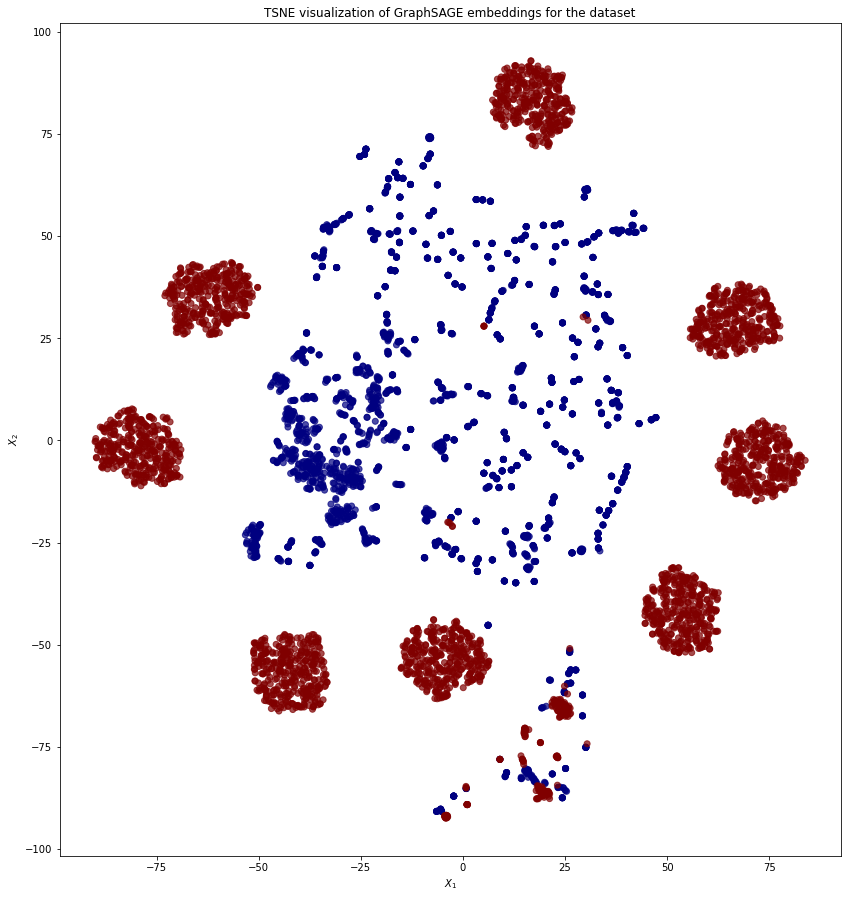

In [34]:
alpha = 0.7

fig, ax = plt.subplots(figsize=(14, 16))
ax.scatter(
    emb_transformed[0],
    emb_transformed[1],
    c=emb_transformed["label"].astype("category"),
    cmap="jet",
    alpha=alpha,
)
ax.set(aspect="equal", xlabel="$X_1$", ylabel="$X_2$")
plt.title(
    "{} visualization of GraphSAGE embeddings for the dataset".format(transform.__name__)
)
plt.show()